In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import zipfile
import copy
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Read data

In [ ]:
drive.mount('/content/gdrive/')
url = '/content/gdrive/My Drive/DASS_project/data/1202_1204.csv'
raw_df = pd.read_csv(url)
url2 = '/content/gdrive/My Drive/DASS_project/data/1204_1213.csv'
raw_df2 = pd.read_csv(url2)
# url2 = '/content/drive/MyDrive/DASS_project/data/1204-1213.zip'
# zip_ref = zipfile.ZipFile("url", 'r')
# zip_ref.extractall("/tmp")
# zip_ref.close()

Mounted at /content/gdrive/


In [ ]:
raw_df2['sno'][1231]

'sno'

### 檔案裡有重複輸入coulmn name

In [ ]:
# drop data columns name
print(raw_df.shape)
# print(raw_df['tot'][1231])
# print(raw_df['tot'][2912447])
# print(raw_df['tot'][2911215])

# drop_index = np.arange(start = 1231, stop = 2912448, step = 1232)
# print(drop_index)
# raw_df = raw_df.drop(drop_index, axis = 0)

raw_df = raw_df[raw_df['sna'] != 'sna']
print(raw_df.shape)

(2913679, 18)
(2911315, 18)


In [ ]:
# drop data columns name
print(raw_df2.shape)
# print(raw_df2['tot'][1231])
# print(raw_df2['tot'][2912447])
# print(raw_df2['tot'][2911215])
# print(raw_df2['tot'][16397919])
# print(raw_df2['tot'][16376975])
# print(raw_df2['tot'][16400674])

# drop_index = np.arange(start = 1231, stop = 16400674+1, step = 1232)
# print(drop_index[-20])
# raw_df = raw_df.drop(drop_index, axis = 0)
raw_df2 = raw_df2[raw_df2['sna'] != 'sna']
print(raw_df2.shape)

(16401908, 18)
(16388593, 18)


In [ ]:
raw_df = raw_df.reset_index()
raw_df2 = raw_df2.reset_index()
raw_df = raw_df.drop(columns = 'index')
raw_df2 = raw_df2.drop(columns = 'index')
raw_df.shape
raw_df2.shape

(16388593, 18)

In [ ]:
raw_df.nunique()

sno              1231
sna              1234
tot                64
sbi                96
sarea              14
mday             9410
lat              1158
lng              1165
ar               1232
sareaen            13
snaen            1225
aren             1228
bemp              100
act                 2
srcUpdateTime    2359
updateTime       2362
infoTime         9410
infoDate            9
dtype: int64

In [ ]:
# merge two df
raw_merged = pd.concat([raw_df, raw_df2], axis = 0)
raw_merged.shape

(19299908, 18)

In [ ]:
raw_merged.columns

Index(['sno', 'sna', 'tot', 'sbi', 'sarea', 'mday', 'lat', 'lng', 'ar',
       'sareaen', 'snaen', 'aren', 'bemp', 'act', 'srcUpdateTime',
       'updateTime', 'infoTime', 'infoDate'],
      dtype='object')

### change data type

In [ ]:
raw_merged.dtypes

sno              object
sna              object
tot              object
sbi              object
sarea            object
mday             object
lat              object
lng              object
ar               object
sareaen          object
snaen            object
aren             object
bemp             object
act              object
srcUpdateTime    object
updateTime       object
infoTime         object
infoDate         object
dtype: object

In [ ]:
raw_merged.columns

Index(['sno', 'sna', 'tot', 'sbi', 'sarea', 'mday', 'lat', 'lng', 'ar',
       'sareaen', 'snaen', 'aren', 'bemp', 'act', 'srcUpdateTime',
       'updateTime', 'infoTime', 'infoDate'],
      dtype='object')

In [ ]:
# temp storage
# raw_merged.to_csv('/content/drive/MyDrive/DASS_project/data/1202_1213raw.csv')

In [ ]:
# raw_merged = pd.read_csv('/content/drive/MyDrive/DASS_project/data/1202_1213raw.csv')

In [ ]:
# drop useless
to_drop = [ 'mday', 'lat', 'lng', 'ar',
       'sareaen', 'snaen', 'aren',  'srcUpdateTime',
       'updateTime']
raw_merged = copy.deepcopy(raw_merged)
raw_merged = raw_merged.drop(columns = to_drop, axis = 1)
raw_merged.shape

(19299908, 9)

In [ ]:
# change type of variables
categories = ['sno', 'sna', 'sarea', 'act']
numeric = ['tot', 'sbi', 'bemp']
datetime = ['infoTime', 'infoDate']

for col in categories:
  raw_merged[col] = pd.Categorical(raw_merged[col])

for col in numeric:
  raw_merged[col] = pd.to_numeric(raw_merged[col])

for col in datetime:
  raw_merged[col] = pd.to_datetime(raw_merged[col])

raw_merged['tot'] = pd.to_numeric(raw_merged['tot'])
raw_merged['sbi'] = pd.to_numeric(raw_merged['sbi'])
raw_merged['bemp'] = pd.to_numeric(raw_merged['bemp'])

to_drop = [ 'mday', 'lat', 'lng', 'ar',
       'sareaen', 'snaen', 'aren',  'srcUpdateTime',
       'updateTime']

In [ ]:
raw_merged.dtypes

sno               category
sna               category
tot                  int64
sbi                  int64
sarea             category
bemp                 int64
act               category
infoTime    datetime64[ns]
infoDate    datetime64[ns]
dtype: object

In [ ]:
raw_merged.nunique()

sno          1233
sna          1236
tot            64
sbi            97
sarea          14
bemp          100
act             2
infoTime    61003
infoDate       18
dtype: int64

In [ ]:
df1 = copy.deepcopy(raw_merged)

In [ ]:
# temp storage
df1.to_csv('/content/gdrive/MyDrive/DASS_project/data/preprocessed_ver.csv')

### check data

In [ ]:
# df1 = pd.read_csv('/content/drive/MyDrive/DASS_project/data/1225ver.csv')

In [ ]:
# df1.columns

Index(['sno', 'sna', 'tot', 'sbi', 'sarea', 'bemp', 'act', 'infoTime',
       'infoDate'],
      dtype='object')

In [ ]:
# df1.rename(columns = {'sno':'station_number'}, inplace = True)
# df1.rename(columns = {'sna':'station_name'}, inplace = True)
# df1.rename(columns = {'tot':'total_num'}, inplace = True)
# df1.rename(columns = {'sbi':'current_num'}, inplace = True)
# df1.rename(columns = {'bemp':'empty_num'}, inplace = True)
# df1.rename(columns = {'sare':'district'}, inplace = True)
# df1.rename(columns = {'infoDate':'date'}, inplace = True)
# df1.rename(columns = {'infoTime':'time'}, inplace = True)
# df1.rename(columns = {'act':'station_status'}, inplace = True)

In [ ]:
# df1.columns

Index(['station_number', 'station_name', 'total_num', 'current_num', 'sarea',
       'empty_num', 'station_status', 'time', 'date'],
      dtype='object')

In [ ]:
df1.nunique()

station_number     1233
station_name       1236
total_num            64
current_num          97
sarea                14
empty_num           100
station_status        2
time              61003
date                 18
dtype: int64

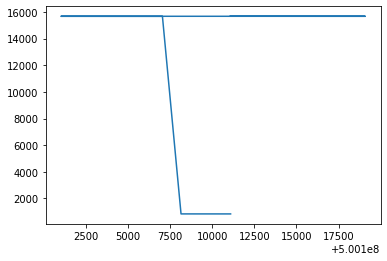

In [ ]:
station = df1['station_number'].value_counts()
plt.plot(station.index, station.values)
plt.show()

In [ ]:
print(station.index[-5:])
print(station.values[-5:])

CategoricalIndex(['500112091', '500104007', '500107034', '500108140',
                  '500111086'],
                 categories=['500101001', '500101002', '500101003', '500101004', '500101005', '500101006', '500101007', '500101008', ...], ordered=False, dtype='category')
[15674 15674 15674   842   841]


編號 500108140 500111086 在raw_df 裡面沒有

In [ ]:
# no data in raw_df 1202-1204
raw_df[raw_df['sno'] == '500108140']

,sno,sna,tot,sbi,sarea,mday,lat,lng,ar,sareaen,snaen,aren,bemp,act,srcUpdateTime,updateTime,infoTime,infoDate


In [ ]:
plt.figure(figsize=(21,9))
sns.heatmap(df1.isnull(),yticklabels=False,cbar=False,cmap='viridis')
plt.show()

In [ ]:
df1['station_number'].describe()

count       2911315
unique         1231
top       500101001
freq           2365
Name: station_number, dtype: object

In [ ]:
pd.isnull(df1)

,station_number,station_name,total_num,current_num,sarea,empty_num,station_status,time,date
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
2911310,False,False,False,False,False,False,False,False,False
2911311,False,False,False,False,False,False,False,False,False
2911312,False,False,False,False,False,False,False,False,False
2911313,False,False,False,False,False,False,False,False,False


In [ ]:
# temp storage
df1.to_csv('/content/drive/MyDrive/DASS_project/data/1224ver.csv')